Load and Preprocess Data

In [1]:
#Imports and Setup
import os
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from PIL import Image
import tensorflow as tf
from tensorflow import keras
from keras import Sequential
from keras.layers import *
from tensorflow.keras.losses import CategoricalCrossentropy
from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.layers import Lambda, GlobalAveragePooling2D, Dense, Dropout, Input
from tensorflow.keras.optimizers import Adam , Adamax
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from sklearn.utils.class_weight import compute_class_weight
from sklearn.utils import class_weight

In [2]:
# Set the path to dataset
test_dir = "C:/Users/MARBLE/Desktop/Python projects/chest_xray_tensorflow/data/chest_xray/big_test_copy"
base_dir = "C:/Users/MARBLE/Desktop/Python projects/chest_xray_tensorflow/data/chest_xray/big_train_copy"

# Set image size
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 123

In [3]:
# Load train and val with split
train_ds = tf.keras.utils.image_dataset_from_directory(
    base_dir,
    validation_split=0.3,
    subset='training',
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical'
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    base_dir,
    validation_split=0.3,
    subset='validation',
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical'
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical'
)

Found 27475 files belonging to 4 classes.
Using 19233 files for training.
Found 27475 files belonging to 4 classes.
Using 8242 files for validation.
Found 968 files belonging to 4 classes.


In [4]:
# data_augmentation
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.2),
    tf.keras.layers.RandomZoom(0.2),
    tf.keras.layers.RandomContrast(0.2),
    tf.keras.layers.RandomTranslation(0.1, 0.1),
])

In [5]:
# Get the actual class labels
y_train = []
for _, labels in train_ds.unbatch():
    y_train.append(np.argmax(labels.numpy()))
class_weights = class_weight.compute_class_weight(class_weight='balanced',
                                                  classes=np.unique(y_train),
                                                  y=y_train)
class_weights_dict = dict(enumerate(class_weights))

In [6]:
# Prefetch for performance
AUTOTUNE = tf.data.AUTOTUNE

# Preprocessing with optional augmentation
def preprocess(ds, augment=False):
    if augment:
        ds = ds.map(lambda x, y: (data_augmentation(x, training=True), y), num_parallel_calls=AUTOTUNE)
    return ds.map(lambda x, y: (preprocess_input(x), y), num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)

# Apply augmentation only to training data
train_ds = preprocess(train_ds, augment=True)
val_ds = preprocess(val_ds)
test_ds = preprocess(test_ds)

**MobileNetV2 Model**

In [7]:
# Build the Model with MobileNetV2
# Load and partially unfreeze MobileNetV2
base_model = MobileNetV2(input_shape=IMG_SIZE + (3,),
                         include_top=False,
                         weights='imagenet')
base_model.trainable = True  # Freeze feature extractor

# Freeze the first N layers
fine_tune_at = 40  # fine-tune from layer 100 onwards
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

# Model definition
model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(4, activation='softmax', kernel_regularizer=regularizers.l2(0.001))
])




In [8]:
# Compile Model
model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss=CategoricalCrossentropy(label_smoothing=0.01),
    metrics=['accuracy']
)

# Summary
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 2,194,948 (8.37 MB)

 Non-trainable params: 68,160 (266.25 KB)

In [9]:
lr_schedule = tf.keras.optimizers.schedules.CosineDecayRestarts(
    initial_learning_rate=1e-4,
    first_decay_steps=1000,
    t_mul=2.0,
    m_mul=0.9,
    alpha=1e-6
)
optimizer = Adam(learning_rate=lr_schedule)

In [10]:
# Add call backs
callbacks = [
    EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=2, min_lr=1e-6),
    ModelCheckpoint('best_model.keras', save_best_only=True)
]

In [11]:
# Train the Model
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=callbacks,
    class_weight=class_weights_dict
)



Epoch 1/30
602/602 ━━━━━━━━━━━━━━━━━━━━ 1583s 3s/step - accuracy: 0.8166 - loss: 0.6613 - val_accuracy: 0.8391 - val_loss: 0.5564 - learning_rate: 1.0000e-04
Epoch 2/30
602/602 ━━━━━━━━━━━━━━━━━━━━ 1586s 3s/step - accuracy: 0.9259 - loss: 0.4416 - val_accuracy: 0.7680 - val_loss: 0.7687 - learning_rate: 1.0000e-04
Epoch 3/30
602/602 ━━━━━━━━━━━━━━━━━━━━ 1585s 3s/step - accuracy: 0.9429 - loss: 0.3896 - val_accuracy: 0.9435 - val_loss: 0.2124 - learning_rate: 1.0000e-04
Epoch 4/30
602/602 ━━━━━━━━━━━━━━━━━━━━ 1578s 3s/step - accuracy: 0.9430 - loss: 0.3858 - val_accuracy: 0.9511 - val_loss: 0.1923 - learning_rate: 1.0000e-04
Epoch 5/30
602/602 ━━━━━━━━━━━━━━━━━━━━ 1569s 3s/step - accuracy: 0.9451 - loss: 0.3822 - val_accuracy: 0.8424 - val_loss: 0.4867 - learning_rate: 1.0000e-04
Epoch 6/30
602/602 ━━━━━━━━━━━━━━━━━━━━ 1572s 3s/step - accuracy: 0.9523 - loss: 0.3578 - val_accuracy: 0.8044 - val_loss: 0.5807 - learning_rate: 1.0000e-04
Epoch 7/30
602/602 ━━━━━━━━━━━━━━━━━━━━ 1589s 3s/ste

In [12]:
test_loss, test_acc = model.evaluate(test_ds)
print(f'Test accuracy: {test_acc:.2%}')


31/31 ━━━━━━━━━━━━━━━━━━━━ 25s 763ms/step - accuracy: 0.8677 - loss: 0.4264
Test accuracy: 86.88%


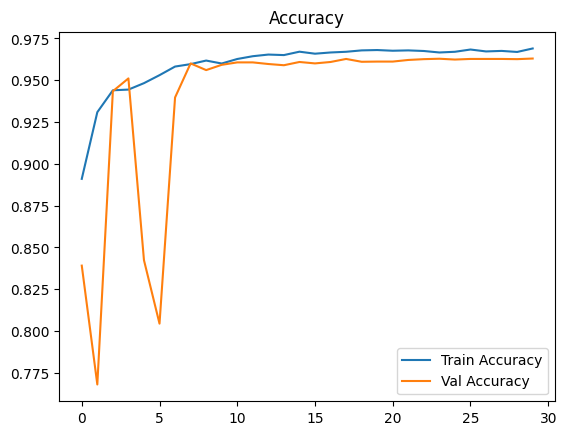

In [13]:
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.legend()
plt.title('Accuracy')
plt.show()

In [14]:
from sklearn.metrics import classification_report, confusion_matrix
import itertools

# Gather true and predicted labels
y_true = []
y_pred = []
for images, labels in test_ds.unbatch():
    preds = model.predict(tf.expand_dims(images, axis=0))
    y_pred.append(np.argmax(preds))
    y_true.append(np.argmax(labels.numpy()))

print(confusion_matrix(y_true, y_pred))
print(classification_report(y_true, y_pred))


1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 100ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step
1/1 ━━

In [16]:
model.save("new_model.h5")
 

In [ ]:
import gradio as gr
import tensorflow as tf
import numpy as np
from PIL import Image

# Load the trained model
model = tf.keras.models.load_model("new_model.h5")

# Define class names
class_names = ["VIRAL_PNEUMONIA", "BACTERIAL_PNEUMONIA", "PNEUMOTHORAX", "NORMAL"]

# Preprocess the uploaded image
def preprocess_image(img: Image.Image) -> np.ndarray:
    img = img.resize((224, 224))
    img = np.array(img) / 255.0
    if img.shape[-1] == 1:
        img = np.repeat(img, 3, axis=-1)
    elif img.shape[-1] != 3:
        img = img[..., :3]
    return img.reshape(1, 224, 224, 3)

# Predict function
def predict_xray(image):
    img = preprocess_image(image)
    preds = model.predict(img)[0]
    results = {class_names[i]: float(preds[i]) for i in range(len(class_names))}
    return results

# Gradio UI setup
title = "🩻 Chest X-Ray Pneumonia Classifier (4-Class)"
description = "Upload a chest X-ray image to check for signs of VIRAL_PNEUMONIA, BACTERIAL_PNEUMONIA, PNEUMOTHORAX, or NORMAL. This model is powered by MobileNetV2."

gr.Interface(
    fn=predict_xray,
    inputs=gr.Image(type="pil", label="Upload Chest X-Ray"),
    outputs=gr.Label(num_top_classes=4, label="Prediction"),
    title=title,
    description=description,
    theme="default",
    allow_flagging="never"
).launch()

c:\Users\MARBLE\Desktop\Python projects\school_management_system\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\MARBLE\Desktop\Python projects\school_management_system\venv\Lib\site-packages\gradio\interface.py:416: UserWarning: The `allow_flagging` parameter in `Interface` is deprecated.Use `flagging_mode` instead.
  warnings.warn(


* Running on local URL:  http://127.0.0.1:7861
* To create a public link, set `share=True` in `launch()`.


1/1 ━━━━━━━━━━━━━━━━━━━━ 71s 71s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 818ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 516ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 511ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 497ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 419ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 778ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 464ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 850ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 971ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 512ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 706ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 573ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 324ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 732ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 528ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 402ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 589ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 575ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 557ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 555ms/step
1/